# Train on PanopTILs Refined

Train a model to find nuclei and identify their cell types. First run
[Prepare PanopTILs](prepare-data.ipynb) to create the images and labels used here.

An epoch is one pass over the training images. This example runs five epochs;
inspect the validation predictions to decide whether to train longer.


## Setup

In [1]:
import json
import random
from pathlib import Path

import albumentations as A
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.patches import Patch
from skimage.color import label2rgb
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader

from cellseg_models_pytorch.inference.post_processor import PostProcessor
from cellseg_models_pytorch.losses import (
    CELoss,
    DiceLoss,
    JointLoss,
    MSE,
    MultiTaskLoss,
)
from cellseg_models_pytorch.metrics import panoptic_quality
from cellseg_models_pytorch.models.cellpose import CellPose
from cellseg_models_pytorch.transforms.albu_transforms import (
    AlbuStrongAugment,
    ApplyEach,
    CellposeTransform,
    MinMaxNormalization,
)
from cellseg_models_pytorch.transforms.functional.normalization import minmax_normalize
from cellseg_models_pytorch.torch_datasets import TrainDatasetFolder
from cellseg_models_pytorch.utils import FileHandler

seed = 42

# Seed the libraries that shuffle data and choose random augmentations.
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.set_num_threads(2)

# Use the GPU when one is available.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

data_root = Path("../../data/panoptils-nuclei")
class_names = [
    "background",
    "neoplastic",
    "stromal",
    "inflammatory",
    "epithelial",
    "other",
    "unknown",
]

print(f"Device: {device}")


Device: cuda


## Load images and labels

Pair each image with its nucleus and cell-type labels. Scale image pixels to 0–1.
For training, flip images and labels together and vary the image colours.
Validation images are scaled without random changes.


In [2]:
# Apply the same spatial changes to images and masks.
train_transforms = A.Compose(
    [
        A.HorizontalFlip(p=0.33),
        A.VerticalFlip(p=0.33),
        AlbuStrongAugment(seed=seed),
        MinMaxNormalization(copy=True),
    ],
    seed=seed,
)

# Keep validation deterministic, with the same image scaling.
validation_transforms = A.Compose([MinMaxNormalization(copy=True)])

# Build flow targets from the augmented nucleus masks.
instance_transforms = ApplyEach([CellposeTransform(deduplicate=False)], as_list=True)

train_dataset = TrainDatasetFolder(
    str(data_root / "train/images"),
    str(data_root / "train/labels"),
    mask_keys=("inst", "type"),
    transforms=train_transforms,
    inst_transforms=instance_transforms,
)
validation_dataset = TrainDatasetFolder(
    str(data_root / "validation/images"),
    str(data_root / "validation/labels"),
    mask_keys=("inst", "type"),
    transforms=validation_transforms,
    inst_transforms=instance_transforms,
)

# Shuffle training patches; keep validation patches in a fixed order.
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=4)
validation_loader = DataLoader(
    validation_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=4,
)

print(f"Patches: {len(train_dataset)} training, {len(validation_dataset)} validation")


Patches: 17536 training, 4048 validation


## Training recipe

Follow the [Histolytics training recipe](https://hautaniemilab.github.io/histolytics/user_guide/seg/finetuning/)
with two outputs: cell types and flows. Flows point nucleus pixels toward their
centre and help separate touching nuclei.

A loss measures prediction error. Use cross-entropy and Dice losses for cell types,
and mean squared error for flows. AdamW updates the weights, while a cosine
schedule gradually lowers the learning rate.


In [2]:
criterion = MultiTaskLoss(
    {
        "cellpose": JointLoss([MSE()]),
        "type_mask": JointLoss([CELoss(apply_sd=True), DiceLoss()]),
    },
    loss_weights={"cellpose": 1.0, "type_mask": 1.0},
).to(device)

learning_rate = 1e-4
num_epochs = 5


## Initialize the network

Start with an EfficientNet-B5 encoder pretrained on ImageNet. The encoder extracts
image features; new segmentation layers learn nuclei and cell types from the labels.
The encoder weights download on first use.

Set `checkpoint_dir` to a new folder for the saved model files.


In [4]:
model = CellPose(
    7,
    enc_name="efficientnet_b5",
    enc_pretrain=True,
    device=device,
).model

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
scheduler = CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=0)

# A new directory protects checkpoints from earlier runs.
checkpoint_dir = Path("training-checkpoints")
checkpoint_dir.mkdir(exist_ok=False)


## Define the training steps

Train on small groups of images, called batches. For each batch, predict the
labels, measure the loss and update the model. Validation measures the loss on
separate images without updating the weights. Save a checkpoint after each epoch.


In [5]:
def prepare_batch(batch: dict[str, torch.Tensor]):
    # Class labels use integers; flow targets use floating-point values.
    images = batch["image"].to(device)
    targets = {
        "type_mask": batch["type"].long().to(device),
        "cellpose": batch["cellpose_inst"].float().to(device),
    }
    return images, targets


def train_epoch(model, loader, optimizer):
    total = 0.0
    for batch in loader:
        images, targets = prepare_batch(batch)

        # Clear old gradients before predicting this batch.
        optimizer.zero_grad(set_to_none=True)
        output = model(images)["nuc"]
        loss = criterion(
            {"type_mask": output.type_map, "cellpose": output.aux_map}, targets
        )

        # Backpropagate the loss, then update the model weights.
        loss.backward()
        optimizer.step()

        # Weight each batch by its size so the last, smaller batch counts correctly.
        total += float(loss.detach()) * images.shape[0]

    return total / len(loader.dataset)


def validate_epoch(model, loader):
    total = 0.0
    with torch.inference_mode():
        for batch in loader:
            images, targets = prepare_batch(batch)

            output = model(images)["nuc"]
            loss = criterion(
                {"type_mask": output.type_map, "cellpose": output.aux_map}, targets
            )

            total += float(loss) * images.shape[0]

    return total / len(loader.dataset)


## Save training progress

Save the model and training state after each epoch so training can resume later.


In [5]:
def save_checkpoint(epoch, phase):
    numpy_rng = np.random.get_state()

    path = checkpoint_dir / f"epoch_{epoch:02d}.pt"
    # Exclusive creation prevents an existing epoch checkpoint from being overwritten.
    with path.open("xb") as destination:
        torch.save(
            {
                "model": model.state_dict(),
                "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(),
                "epoch": epoch,
                "phase": phase,
                "encoder": model.enc_name,
                "class_names": class_names,
                "torch_rng": torch.get_rng_state(),
                "cuda_rng": torch.cuda.get_rng_state(device)
                if device.type == "cuda"
                else None,
                "python_rng": random.getstate(),
                "numpy_rng": (numpy_rng[0], numpy_rng[1].tolist(), *numpy_rng[2:]),
                "data_manifest": json.loads((data_root / "manifest.json").read_text()),
                "normalization": "global min-max, RGB float32",
                "augmentation_seed": seed,
                "num_workers": train_loader.num_workers,
                "num_epochs": num_epochs,
                "training_loss": training_loss,
                "validation_loss": validation_loss,
            },
            destination,
        )

    return path


## Train and validate


In [6]:
for epoch in range(num_epochs):
    # Use new random augmentations on each pass through the training set.
    train_transforms.set_random_seed(seed + epoch)
    model.train()
    training_loss = train_epoch(model, train_loader, optimizer)

    # Validation changes neither weights nor BatchNorm statistics.
    model.eval()
    validation_loss = validate_epoch(model, validation_loader)

    # Advance the learning-rate schedule and save the completed epoch.
    scheduler.step()
    saved_checkpoint = save_checkpoint(epoch + 1, "unfrozen")

    print(
        f"Epoch {epoch + 1}: training loss {training_loss:.3f}, "
        f"validation loss {validation_loss:.3f}"
    )


Epoch 1: training loss 1.172, validation loss 0.820


Epoch 2: training loss 0.964, validation loss 0.767


Epoch 3: training loss 0.909, validation loss 0.752


Epoch 4: training loss 0.868, validation loss 0.735


Epoch 5: training loss 0.841, validation loss 0.828


## Load the saved model

Load the last checkpoint to make predictions. It also contains the training state
needed to resume an interrupted run.


In [4]:
state = torch.load(saved_checkpoint, map_location="cpu", weights_only=True)
inference_model = CellPose(
    len(state["class_names"]),
    enc_name=state["encoder"],
    enc_pretrain=False,
    device=device,
)

restored = inference_model.model
restored.load_state_dict(state["model"], strict=True)

# Restore optimizer and scheduler state to keep the training schedule.
resumed_optimizer = torch.optim.AdamW(restored.parameters(), lr=learning_rate)
resumed_scheduler = CosineAnnealingLR(
    resumed_optimizer, T_max=state["scheduler"]["T_max"]
)
resumed_optimizer.load_state_dict(state["optimizer"])
resumed_scheduler.load_state_dict(state["scheduler"])


# Restore random states so a resumed run continues from this epoch.
random.setstate(state["python_rng"])
np.random.set_state(state["numpy_rng"])
torch.set_rng_state(state["torch_rng"])

if device.type == "cuda" and state["cuda_rng"] is not None:
    torch.cuda.set_rng_state(state["cuda_rng"], device)


# Switch to prediction mode before evaluating the reloaded weights.
inference_model.set_inference_mode(mixed_precision=False)
inference_model.post_processor = PostProcessor(
    "cellpose", {"use_gpu": device.type == "cuda"}
)

print("Reloaded model, optimizer and scheduler after epoch", state["epoch"])


Reloaded model, optimizer and scheduler after epoch 5


## Check predictions on validation images

Predict nuclei in 16 validation images at their original 1024-pixel size. These
images come from patients that were not used for training.

Panoptic quality (PQ) measures how well predicted nuclei match the labels:
1 is perfect and 0 means no matches. The table shows the average score and nucleus
counts. Cell-type scores require both the correct type and a matching nucleus;
they average only images where that type appears in the labels or predictions.
`NaN` means there were no cells of that type to score. These results describe the
16 example images; inspect the masks too, especially for rare types.


In [5]:
region_paths = sorted((data_root / "validation/regions/images").glob("*.png"))

# Evaluate 16 validation images from patients outside the training set.
evaluation_paths = region_paths[:: max(1, len(region_paths) // 16)][:16]

records = []

for path in evaluation_paths:
    raw_image = FileHandler.read_img(path)
    labels = FileHandler.read_mat(
        data_root / "validation/regions/labels" / f"{path.stem}.mat"
    )

    # Use the same RGB scaling as the training and validation datasets.
    image = minmax_normalize(raw_image, copy=True)
    result = inference_model.post_process(
        inference_model.predict(image),
        use_async_postproc=False,
    )
    predicted_instances, predicted_classes = result["nuc"][0]

    records.append(
        {
            "class": "all nuclei",
            "PQ": panoptic_quality(labels["inst"], predicted_instances)["pq"],
            "target objects": len(np.unique(labels["inst"][labels["inst"] > 0])),
            "predicted objects": len(
                np.unique(predicted_instances[predicted_instances > 0])
            ),
        }
    )

    # Score each cell type separately to reveal weak performance on rare types.
    for class_id, name in enumerate(class_names[1:], start=1):
        true_class = np.where(labels["type"] == class_id, labels["inst"], 0)
        predicted_class = np.where(
            predicted_classes == class_id, predicted_instances, 0
        )
        true_count = len(np.unique(true_class[true_class > 0]))
        predicted_count = len(np.unique(predicted_class[predicted_class > 0]))
        score = panoptic_quality(true_class, predicted_class)["pq"]
        records.append(
            {
                "class": name,
                "PQ": score if true_count + predicted_count else np.nan,
                "target objects": true_count,
                "predicted objects": predicted_count,
            }
        )

# Average PQ over images; sum nucleus counts across all evaluated regions.
metrics = (
    pd.DataFrame(records)
    .groupby("class", sort=False)
    .agg(
        {
            "PQ": "mean",
            "target objects": "sum",
            "predicted objects": "sum",
        }
    )
    .round(3)
)

print(f"Held-out regions: {len(evaluation_paths)}")
metrics


Held-out regions: 16


,PQ,target objects,predicted objects
class,,,
all nuclei,0.643,6756,7192
neoplastic,0.509,3082,2860
stromal,0.361,1740,1986
inflammatory,0.308,1202,1115
epithelial,NaN,0,0
other,0.000,3,0
unknown,0.219,657,1231


## Compare the masks

Both rows show the same validation image. The top row shows the dataset labels;
the bottom row shows predictions. Look for missed nuclei, merged neighbours and
incorrect cell types using the shared legend.

Gray means the dataset labels a nucleus as “unknown”. Many nuclei in this
example have that label.


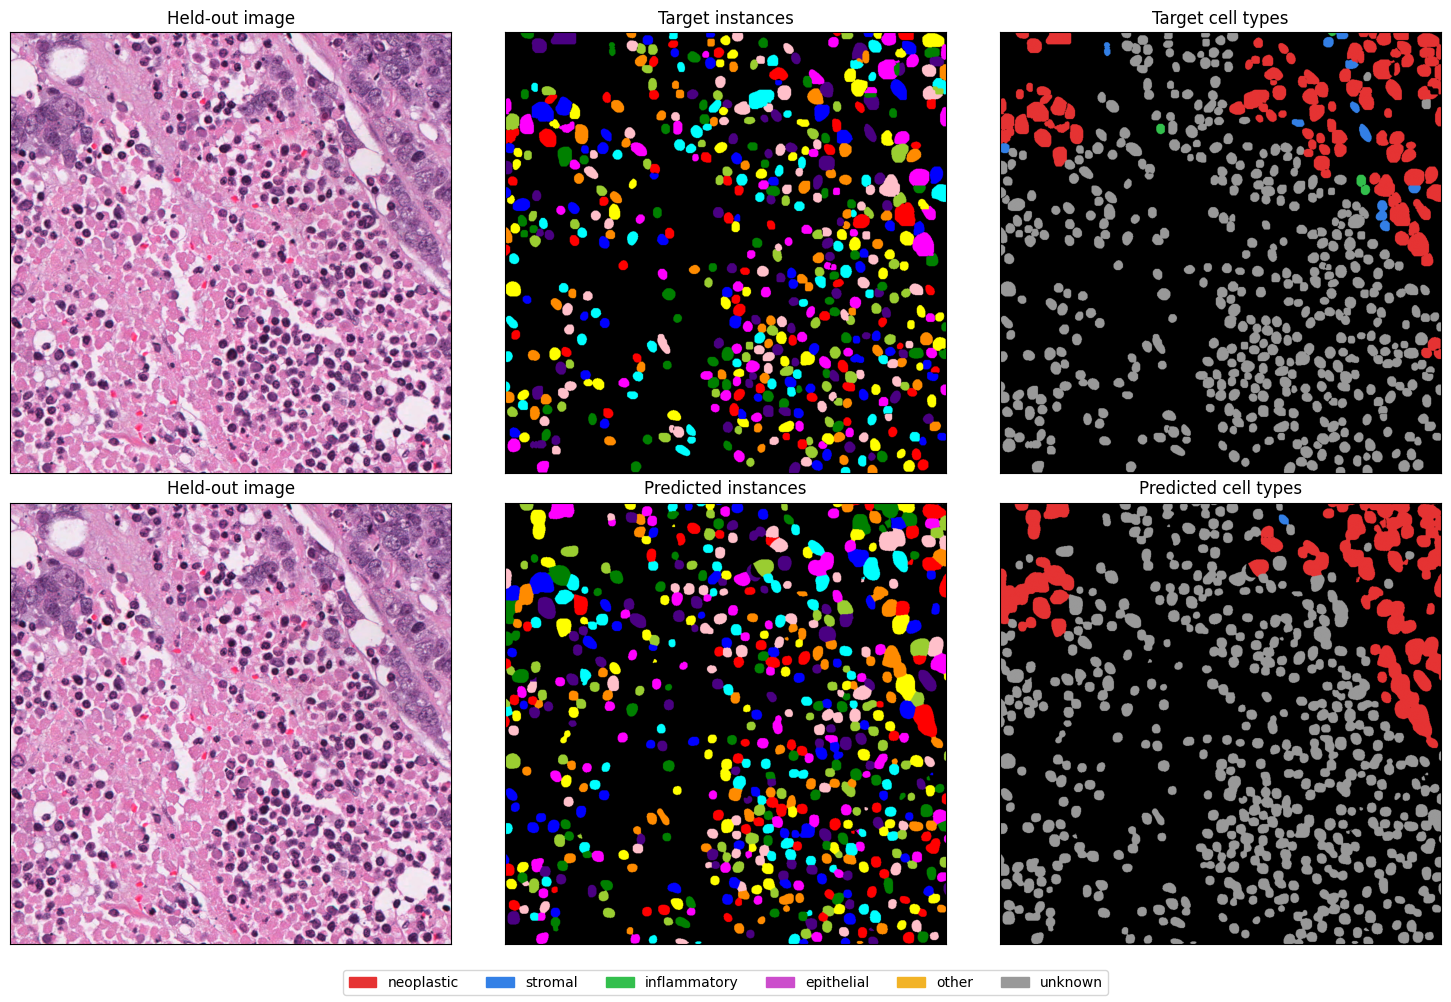

In [6]:
# Compare predictions with the labels for one validation image.
path = evaluation_paths[0]
raw_image = FileHandler.read_img(path)
labels = FileHandler.read_mat(
    data_root / "validation/regions/labels" / f"{path.stem}.mat"
)

image = minmax_normalize(raw_image, copy=True)
result = inference_model.post_process(
    inference_model.predict(image), use_async_postproc=False
)
predicted_instances, predicted_classes = result["nuc"][0]

# Fixed colours keep each class identical in target and prediction panels.
class_palette = np.array(
    [
        [0, 0, 0],
        [0.9, 0.2, 0.2],
        [0.2, 0.5, 0.9],
        [0.2, 0.75, 0.3],
        [0.8, 0.3, 0.8],
        [0.95, 0.7, 0.15],
        [0.6, 0.6, 0.6],
    ]
)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes[0, 0].imshow(raw_image)
axes[0, 0].set_title("Held-out image")

axes[0, 1].imshow(label2rgb(labels["inst"], bg_label=0))
axes[0, 1].set_title("Target instances")

axes[0, 2].imshow(class_palette[labels["type"].astype(int)])
axes[0, 2].set_title("Target cell types")

axes[1, 0].imshow(raw_image)
axes[1, 0].set_title("Held-out image")

axes[1, 1].imshow(label2rgb(predicted_instances, bg_label=0))
axes[1, 1].set_title("Predicted instances")

axes[1, 2].imshow(class_palette[predicted_classes])
axes[1, 2].set_title("Predicted cell types")

for axis in axes.flat:
    axis.set(xticks=[], yticks=[])

fig.legend(
    [Patch(color=colour) for colour in class_palette[1:]],
    class_names[1:],
    loc="lower center",
    ncol=6,
)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()
